# 06 — Le FeedForward : ReLU et dropout

**Chapitre 2** · durée conseillée : 25 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/fr/chapitre_2/06_feedforward.ipynb)

![Parcours](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/fr/chapitre_2/figures/00_parcours.png)

Après l'attention, chaque position a **reçu** de l'information de son passé : son vecteur est une moyenne pondérée de valeurs. Mais une moyenne pondérée reste une opération presque **linéaire**. Il faut maintenant que chaque position **traite** ce qu'elle a reçu : combiner des indices, détecter des motifs (« après `q` vient `u` », « on est au début d'un nom de personnage »…). C'est le rôle du **FeedForward**.

**À la fin de ce notebook, vous saurez :**
1. expliquer la formule du FeedForward et l'élargissement `C → 4C → C` ;
2. montrer pourquoi une **non-linéarité** (ReLU) est indispensable ;
3. vérifier que le FeedForward traite chaque position **séparément** ;
4. expliquer le **dropout**, et la différence entre `model.train()` et `model.eval()`.

In [ ]:
# Sur Google Colab : récupérer le dépôt du cours (corpus + modules partagés comme minigpt.py).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/fr/chapitre_2

In [1]:
# Préparation : imports et module partagé du chapitre
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # fichier minigpt.py, à côté de ce notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| périphérique :", device)

PyTorch 2.14.1+cu130 | périphérique : cpu


## Rappel
<img src="https://upload.wikimedia.org/wikipedia/commons/3/34/Transformer%2C_full_architecture.png" alt="Architecture originale encodeur-décodeur d'un Transformer" width="560" style="background:white"/>

*Illustration : dvgodoy, [Wikimedia Commons — Transformer, full architecture](https://commons.wikimedia.org/wiki/File:Transformer,_full_architecture.png), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), reproduite sans modification.*

## 1. La formule

Dans le papier (équation 2), pour **chaque position** de vecteur $x \in \mathbb{R}^C$ :

$$\text{FFN}(x) = \max(0,\ x W_1 + b_1)\, W_2 + b_2 \qquad W_1 \in \mathbb{R}^{C \times 4C},\quad W_2 \in \mathbb{R}^{4C \times C}$$

![FeedForward](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/fr/chapitre_2/figures/06_feedforward.png)

1. **Élargir** : `Linear(C, 4C)` projette dans un espace 4 fois plus grand, où il y a de la place pour détecter beaucoup de motifs différents (chaque neurone caché ≈ un détecteur).
2. **Non-linéarité** : `ReLU(z) = max(0, z)` ne garde que les détecteurs « activés ».
3. **Revenir** : `Linear(4C, C)` recombine les détecteurs activés en un vecteur de taille `C`, pour pouvoir l'**additionner** au flux résiduel (notebook 07).
4. **Dropout** : régularisation (§5).

**Attention = communication entre positions. FeedForward = calcul à l'intérieur de chaque position.**

## 2. Pourquoi une non-linéarité ? Sans elle, deux couches = une seule

Deux couches linéaires d'affilée se simplifient : $(x W_1) W_2 = x (W_1 W_2)$. Empiler des couches linéaires, aussi larges soient-elles, ne donne **jamais** qu'une seule application linéaire. Vérifions-le.

In [2]:
torch.manual_seed(0)
lin1, lin2 = nn.Linear(8, 32, bias=False), nn.Linear(32, 8, bias=False)
x = torch.randn(5, 8)

deux_couches = lin2(lin1(x))
une_seule = x @ (lin1.weight.T @ lin2.weight.T)           # W = W1 @ W2, de taille (8, 8)
print("Linear∘Linear == une seule Linear ?", torch.allclose(deux_couches, une_seule, atol=1e-6))

avec_relu = lin2(F.relu(lin1(x)))
print("Linear∘ReLU∘Linear == cette Linear ?", torch.allclose(avec_relu, une_seule, atol=1e-6))

Linear∘Linear == une seule Linear ? True
Linear∘ReLU∘Linear == cette Linear ? False


### Expérience : apprendre une fonction non linéaire

Essayons d'apprendre $y = \sin(3x)$ avec deux réseaux de **même taille**, l'un sans activation, l'autre avec ReLU.

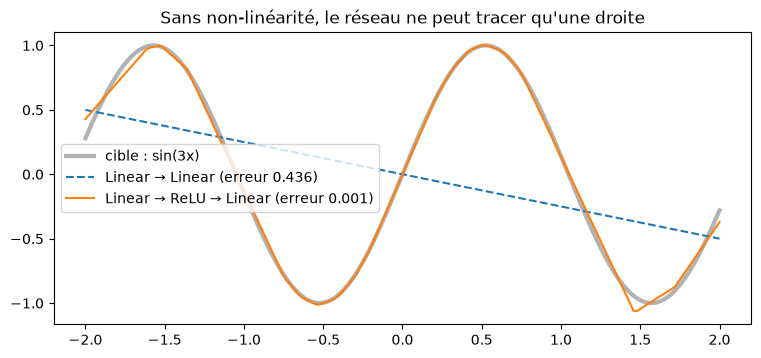

In [3]:
torch.manual_seed(0)
xs = torch.linspace(-2, 2, 200).unsqueeze(1)
ys = torch.sin(3 * xs)

def ajuster(reseau, pas=2000):
    opt = torch.optim.AdamW(reseau.parameters(), lr=1e-2)
    for _ in range(pas):
        loss = F.mse_loss(reseau(xs), ys)
        opt.zero_grad(); loss.backward(); opt.step()
    return loss.item()

sans = nn.Sequential(nn.Linear(1, 64), nn.Linear(64, 1))
avec = nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Linear(64, 1))
l_sans, l_avec = ajuster(sans), ajuster(avec)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(xs, ys, "k", lw=3, alpha=.3, label="cible : sin(3x)")
ax.plot(xs, sans(xs).detach(), "--", label=f"Linear → Linear (erreur {l_sans:.3f})")
ax.plot(xs, avec(xs).detach(), label=f"Linear → ReLU → Linear (erreur {l_avec:.3f})")
ax.legend(); ax.set_title("Sans non-linéarité, le réseau ne peut tracer qu'une droite"); plt.show()

Le réseau avec ReLU approche la sinusoïde par **morceaux de droites** : chaque neurone caché ajoute un « coude » à l'endroit où son entrée passe par zéro. Plus il y a de neurones, plus on peut faire de coudes : c'est l'intérêt d'élargir à `4C`.

## 3. ReLU

$$\text{ReLU}(z) = \max(0, z) \qquad \text{ReLU}'(z) = \begin{cases} 1 & z > 0 \\ 0 & z < 0 \end{cases}$$

- **Simple et rapide** : une comparaison.
- **Gradient non écrasé** : quand le neurone est actif, la dérivée vaut exactement 1 (contrairement à `tanh` ou `sigmoïde` qui saturent). C'est ce qui a permis d'entraîner des réseaux profonds (Glorot et al., 2011).
- **Inconvénient** : un neurone dont l'entrée est toujours négative ne reçoit **plus aucun gradient** (« neurone mort »). Des variantes lissées comme **GELU** (utilisée par GPT-2 et BERT) gardent un petit gradient pour les valeurs négatives.

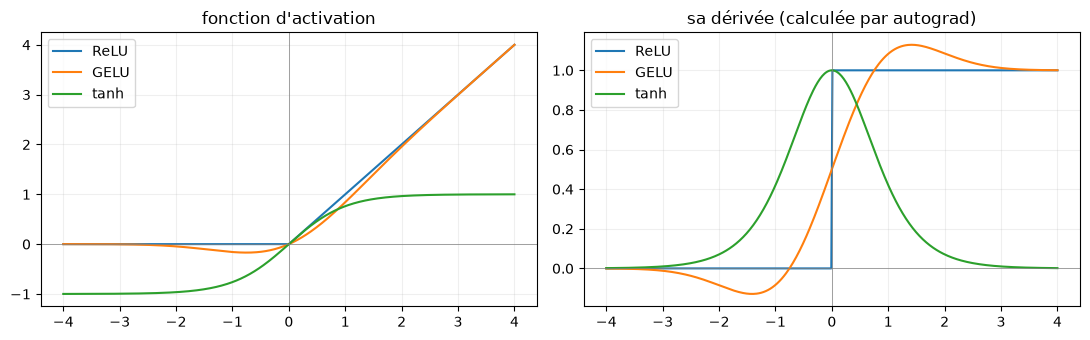

In [4]:
z = torch.linspace(-4, 4, 400, requires_grad=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for nom, f in [("ReLU", F.relu), ("GELU", F.gelu), ("tanh", torch.tanh)]:
    y = f(z)
    g, = torch.autograd.grad(y.sum(), z)
    axes[0].plot(z.detach(), y.detach(), label=nom)
    axes[1].plot(z.detach(), g, label=nom)
axes[0].set_title("fonction d'activation"); axes[1].set_title("sa dérivée (calculée par autograd)")
for ax in axes: ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 4. Chaque position est traitée séparément

`nn.Linear` appliqué à un tenseur `(B, T, C)` agit sur **le dernier axe seulement** : c'est la même matrice appliquée à chacun des `B × T` vecteurs. Conséquence : modifier la position 5 ne change **que** la sortie de la position 5. Comparons avec l'attention, où la modification se propage vers les positions suivantes.

In [5]:
class FeedForward(nn.Module):
    """Petit réseau appliqué indépendamment à chaque position : C -> 4C -> ReLU -> C."""

    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


torch.manual_seed(0)
C = 16
ff = FeedForward(C, dropout=0.0)
att = minigpt.MultiHeadAttention(C, n_head=4, block_size=10, dropout=0.0)
x = torch.randn(1, 10, C)
x_modif = x.clone(); x_modif[0, 5] += 1.0          # on ne touche qu'à la position 5

for nom, couche in [("FeedForward", ff), ("Attention", att)]:
    d = (couche(x) - couche(x_modif)).abs().amax(-1)[0]
    print(f"{nom:12s} positions modifiées : {[t for t in range(10) if d[t] > 1e-6]}")
print("\nFeedForward : (B, T, C) =", tuple(x.shape), "->", tuple(ff.net[0](x).shape), "->", tuple(ff(x).shape))

FeedForward  positions modifiées : [5]
Attention    positions modifiées : [5, 6, 7, 8, 9]

FeedForward : (B, T, C) = (1, 10, 16) -> (1, 10, 64) -> (1, 10, 16)


- **FeedForward** : seule la position 5 change → aucune communication entre positions.
- **Attention** : les positions 5 à 9 changent (elles « voient » la 5), les positions 0 à 4 non (masque causal).

### Le FeedForward pèse lourd

Avec `C = 64` : `Linear(64, 256)` + `Linear(256, 64)` ≈ 33 000 paramètres, contre ≈ 16 600 pour l'attention multi-têtes. Le FeedForward contient **environ deux tiers** des paramètres d'un bloc. Des travaux d'interprétabilité suggèrent qu'il joue le rôle d'une **mémoire clé-valeur** : les lignes de $W_1$ détectent des motifs, celles de $W_2$ écrivent l'information associée (Geva et al., 2021).

In [6]:
C = 64
print("FeedForward :", minigpt.compter_parametres(minigpt.FeedForward(C, 0.0)))
print("Attention   :", minigpt.compter_parametres(minigpt.MultiHeadAttention(C, 4, 64, 0.0)))

FeedForward : 33088
Attention   : 16448


---
## 5. Le dropout

Notre modèle a des centaines de milliers de paramètres ; Shakespeare un million de caractères. Un réseau assez grand peut **apprendre par cœur** les données d'entraînement au lieu d'en extraire des règles : c'est le **surapprentissage**.

**Le dropout** (Srivastava et al., 2014) : pendant l'entraînement, à chaque passage, on **met à zéro chaque valeur avec une probabilité `p`**, au hasard. Le réseau ne peut plus compter sur un neurone précis : il doit répartir l'information et devient plus robuste. On peut le voir comme l'entraînement d'un grand nombre de sous-réseaux différents qui partagent leurs poids.

**Deux détails importants :**
1. Les valeurs conservées sont **multipliées par `1/(1−p)`**, pour que la moyenne ne change pas.
2. Le dropout n'est actif **qu'en mode entraînement** (`model.train()`). En évaluation et en génération (`model.eval()`), il ne fait **rien**.

In [7]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.2)
x = torch.ones(2, 10)

drop.train()
y = drop(x)
print("mode train :\n", y)
print(f"proportion de zéros : {(y == 0).float().mean():.2f}  | valeurs gardées : {1 / (1 - 0.2):.2f} = 1/(1-p)")
print("moyenne sur 100 000 valeurs :", drop(torch.ones(100_000)).mean().item())

drop.eval()
print("\nmode eval :\n", drop(x))

mode train :
 tensor([[0.0000, 1.2500, 1.2500, 0.0000, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500,
         1.2500],
        [1.2500, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500,
         1.2500]])
proportion de zéros : 0.10  | valeurs gardées : 1.25 = 1/(1-p)
moyenne sur 100 000 valeurs : 0.9991875290870667

mode eval :
 tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])


In [8]:
# Conséquence pratique : en mode train, deux passages identiques donnent deux résultats différents.
torch.manual_seed(0)
ff = minigpt.FeedForward(16, dropout=0.2)
x = torch.randn(1, 3, 16)
ff.train(); print("train : mêmes sorties ?", torch.equal(ff(x), ff(x)))
ff.eval();  print("eval  : mêmes sorties ?", torch.equal(ff(x), ff(x)))

train : mêmes sorties ? False
eval  : mêmes sorties ? True


**Où est le [dropout](https://gebob19.github.io/assets/dropout/dattn.pdf) dans notre GPT ?** À trois endroits, avec `p = 0.2` par défaut :
1. sur les **poids d'attention** de chaque tête (une position « oublie » au hasard certaines sources) ;
2. après la **projection** de la multi-head attention ;
3. à la fin du **FeedForward**.

C'est pourquoi `estimate_loss` (notebook 09) appelle `model.eval()` avant de mesurer, puis `model.train()` après.

## À retenir

- **FeedForward** = `Linear(C, 4C) → ReLU → Linear(4C, C) → Dropout`, appliqué **indépendamment à chaque position**. Forme conservée : `(B, T, C)`.
- Sans **non-linéarité**, empiler des couches linéaires ne sert à rien : elles se réduisent à une seule.
- **ReLU** : simple, gradient de 1 quand elle est active ; GELU en est une version lissée.
- **Dropout** : zéros aléatoires (proba `p`) + multiplication par `1/(1−p)`, uniquement en `train()`. Il combat le surapprentissage.

**Questions de vérification**
1. Pourquoi le FeedForward doit-il revenir à `C` canaux en sortie ?
2. Modifier le caractère à la position 3 change-t-il la sortie du FeedForward à la position 4 ? Et celle de l'attention ?
3. Pourquoi faut-il impérativement passer en `model.eval()` avant de générer du texte ?

**Suite → 07 :** nous avons toutes les pièces d'un bloc. Comment s'enchaînent-elles, et comment le gradient les traverse-t-il ?

### Références
- Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762), NeurIPS 2017 — §3.3, équation (2).
- V. Nair & G. Hinton, [*Rectified Linear Units Improve Restricted Boltzmann Machines*](https://www.cs.toronto.edu/~hinton/absps/reluICML.pdf), ICML 2010.
- X. Glorot, A. Bordes, Y. Bengio, [*Deep Sparse Rectifier Neural Networks*](https://proceedings.mlr.press/v15/glorot11a.html), AISTATS 2011.
- D. Hendrycks & K. Gimpel, [*Gaussian Error Linear Units (GELUs)*](https://arxiv.org/abs/1606.08415), 2016.
- N. Srivastava et al., [*Dropout: A Simple Way to Prevent Neural Networks from Overfitting*](https://jmlr.org/papers/v15/srivastava14a.html), JMLR 2014.
- M. Geva et al., [*Transformer Feed-Forward Layers Are Key-Value Memories*](https://arxiv.org/abs/2012.14913), EMNLP 2021.